# CIS 5450 — Olist Delivery Delay Prediction

This notebook uses simulation-based hypothesis tests to evaluate whether two order characteristics are associated with late delivery. It builds on the cleaned dataset from `01_data_cleaning.ipynb` and the findings in `02_EDA.ipynb`.

We investigate two hypotheses:

**Hypothesis 1 — Order Complexity**
- H₀: Single-seller and multi-seller orders have equal late-delivery rates.
- H₁: Their late-delivery rates differ.

**Hypothesis 2 — Shipping Costs**
- H₀: High- and low-shipping-cost orders have equal late-delivery rates.
- H₁: Their late-delivery rates differ.

We use **two-sided permutation tests** and **bootstrap confidence intervals** to evaluate these relationships (Parts 2–4). Because the data are observational, a short set of **robustness checks** in Part 5 examines whether the results could be explained by time, geography, or the promised delivery window. Those checks were added after the EDA and are reported as sensitivity analyses.

## Part 1: Setup

### 1. Imports and file paths

In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from scipy.stats import hypergeom
import statsmodels.formula.api as smf

# Read the cleaned dataset directly from GitHub.
data_path = (
    'https://raw.githubusercontent.com/ZGXJason/CIS5450_FINAL_PROJECT/'
    'main/data/processed/olist_cleaned.csv'
)

BLUE, ORANGE, GRAY, INK = '#2a78d6', '#eb6834', '#8a8984', '#52514e'
plt.rcParams.update({
    'figure.dpi': 110,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.alpha': 0.3,
    'axes.titleweight': 'bold',
})

print(f'Cleaned data URL: {data_path}')

Cleaned data URL: https://raw.githubusercontent.com/ZGXJason/CIS5450_FINAL_PROJECT/main/data/processed/olist_cleaned.csv


### 2. Load the cleaned dataset

Load the order-level dataset and define the outcome and the two group indicators.

In [3]:
df = pd.read_csv(
    data_path,
    parse_dates=['order_purchase_timestamp'],
    dtype={'customer_zip_code_prefix': 'string'}
)

y = df['late_delivery'].to_numpy()

# Hypothesis 1: more than one distinct seller in the order
multi_seller = (df['seller_count'] > 1).to_numpy()

# Hypothesis 2: total freight above the median
freight_median = df['total_freight'].median()
high_freight = (df['total_freight'] > freight_median).to_numpy()

print('Dataset shape:', df.shape)
print('Duplicate order IDs:', df['order_id'].duplicated().sum())
print('Missing values in test columns:',
      df[['late_delivery', 'seller_count', 'total_freight']].isna().sum().sum())
print(f'Overall late delivery rate: {y.mean():.2%}')
print(f'Median total freight: R$ {freight_median:.2f}')

Dataset shape: (95104, 22)
Duplicate order IDs: 0
Missing values in test columns: 0
Overall late delivery rate: 6.84%
Median total freight: R$ 17.16


### 3. Test design and helper functions

**Test statistic.** For each hypothesis, the statistic is the difference in late-delivery rates between the two groups:

$$\Delta = \hat p_{\text{group 1}} - \hat p_{\text{group 0}}$$

**Permutation test.** Under H₀, the group label is unrelated to the outcome, so the labels are exchangeable. We randomly shuffle the labels 10,000 times and recompute Δ each time to build the null distribution. Because H₁ is two-sided, the p-value is the share of shuffled statistics with $|\Delta_{perm}| \ge |\Delta_{obs}|$. With 10,000 shuffles, the smallest reportable p-value is 1/10,000. Because the outcome is binary, we also report the exact permutation p-value, which follows a hypergeometric distribution.

**Bootstrap confidence interval.** We resample orders with replacement *within each group* 10,000 times, recompute Δ, and take the 2.5th and 97.5th percentiles as a 95% CI.

**Significance level.** α = 0.05. Because two hypotheses are tested, the p-values are corrected with the **Holm** method, which controls the family-wise error rate.

All simulations use a fixed random seed and are vectorized in batches.

In [4]:
N_ITER = 10_000
ALPHA = 0.05
SEED = 5450


def rate_difference(y, group):
    """Late rate of group 1 minus late rate of group 0."""
    return y[group].mean() - y[~group].mean()


def permutation_null(y, group, n_iter=N_ITER, seed=SEED, batch=250):
    """Null distribution of the rate difference under random label shuffling."""
    rng = np.random.default_rng(seed)
    y32 = y.astype(np.float32)
    n1, n0 = group.sum(), (~group).sum()
    total_late = y32.sum()
    null = np.empty(n_iter)
    for start in range(0, n_iter, batch):
        b = min(batch, n_iter - start)
        perm = rng.permuted(np.tile(group, (b, 1)), axis=1).astype(np.float32)
        late1 = perm @ y32
        null[start:start + b] = late1 / n1 - (total_late - late1) / n0
    return null


def two_sided_p(null, observed):
    """Share of null statistics at least as extreme as the observed one."""
    return np.mean(np.abs(null) >= abs(observed))


def exact_permutation_p(y, group):
    """Exact two-sided permutation p-value for a difference in proportions.

    Under random relabeling, the number of late orders in group 1 is hypergeometric.
    """
    N, K, n1 = len(y), int(y.sum()), int(group.sum())
    n0 = N - n1
    counts = np.arange(max(0, n1 - (N - K)), min(n1, K) + 1)
    diffs = counts / n1 - (K - counts) / n0
    pmf = hypergeom(N, K, n1).pmf(counts)
    return pmf[np.abs(diffs) >= abs(rate_difference(y, group)) - 1e-12].sum()


def format_p(p, n_iter=N_ITER):
    return f'< {1 / n_iter:.0e} (0 of {n_iter:,} permutations)' if p == 0 else f'{p:.4f}'


def bootstrap_difference(y, group, n_boot=N_ITER, seed=SEED, batch=100):
    """Bootstrap distribution of the rate difference (resampling within each group)."""
    rng = np.random.default_rng(seed)
    y1, y0 = y[group].astype(np.float32), y[~group].astype(np.float32)
    boots = np.empty(n_boot)
    for start in range(0, n_boot, batch):
        b = min(batch, n_boot - start)
        m1 = y1[rng.integers(0, len(y1), (b, len(y1)))].mean(axis=1)
        m0 = y0[rng.integers(0, len(y0), (b, len(y0)))].mean(axis=1)
        boots[start:start + b] = m1 - m0
    return boots


def percentile_ci(boots, level=0.95):
    tail = (1 - level) / 2 * 100
    return np.percentile(boots, tail), np.percentile(boots, 100 - tail)


def group_summary(y, group, labels):
    """Order count, late count, and late rate for the two groups."""
    rows = []
    for name, mask in [(labels[1], group), (labels[0], ~group)]:
        rows.append({'group': name, 'orders': mask.sum(),
                     'late_orders': int(y[mask].sum()), 'late_rate': y[mask].mean()})
    return pd.DataFrame(rows).set_index('group')

In [5]:
def plot_null(ax, null, observed, title, xlabel):
    """Histogram of a permutation null with the observed statistic and its mirror."""
    lo = min(null.min(), -abs(observed)); hi = max(null.max(), abs(observed))
    pad = (hi - lo) * 0.08
    ax.hist(null, bins=60, color=BLUE, alpha=0.85, label='Permutation null')
    ax.axvline(observed, color=ORANGE, linewidth=2, label=f'Observed = {observed * 100:+.2f} pp')
    ax.axvline(-observed, color=ORANGE, linewidth=2, linestyle='--', label='Mirror (two-sided)')
    ax.set_xlim(lo - pad, hi + pad)
    ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f'{v * 100:+.1f}'))
    ax.set_title(title)
    ax.set_xlabel(xlabel + ' (percentage points)')
    ax.set_ylabel('Frequency')
    ax.legend(fontsize=8, loc='best')


def plot_bootstrap(ax, boots, ci, observed, title, xlabel):
    """Histogram of a bootstrap distribution with its 95% CI and the null value 0."""
    ax.hist(boots, bins=60, color=BLUE, alpha=0.85, label='Bootstrap distribution')
    ax.axvspan(ci[0], ci[1], color=BLUE, alpha=0.12,
               label=f'95% CI [{ci[0] * 100:+.2f}, {ci[1] * 100:+.2f}] pp')
    ax.axvline(observed, color=ORANGE, linewidth=2, label=f'Observed = {observed * 100:+.2f} pp')
    ax.axvline(0, color=INK, linewidth=1, linestyle=':', label='No difference')
    ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f'{v * 100:+.1f}'))
    ax.set_title(title)
    ax.set_xlabel(xlabel + ' (percentage points)')
    ax.set_ylabel('Frequency')
    ax.legend(fontsize=8, loc='best')

## Part 2: Hypothesis 1 — Order Complexity

### 4. Observed late-delivery rates

An order is **multi-seller** if its items come from more than one distinct seller (`seller_count > 1`). Group 1 = multi-seller, group 0 = single-seller, so Δ < 0 means multi-seller orders are late less often.

In [6]:
h1_summary = group_summary(y, multi_seller, ('Single-seller', 'Multi-seller'))
display(h1_summary.round(4))

h1_observed = rate_difference(y, multi_seller)
print(f'Observed difference (multi - single): {h1_observed * 100:+.2f} percentage points')
print(f'Risk ratio (multi / single): {y[multi_seller].mean() / y[~multi_seller].mean():.3f}')

,orders,late_orders,late_rate
group,,,
Multi-seller,1242,13,0.0105
Single-seller,93862,6495,0.0692


Observed difference (multi - single): -5.87 percentage points
Risk ratio (multi / single): 0.151


### 5. Two-sided permutation test

Shuffle the multi-seller labels 10,000 times and compare the observed difference with the null distribution. The multi-seller group has only 13 late orders, so we also check the null quantiles to make sure the tails are well behaved.

In [7]:
h1_null = permutation_null(y, multi_seller)
h1_p = two_sided_p(h1_null, h1_observed)
h1_exact_p = exact_permutation_p(y, multi_seller)

print(f'Null distribution: mean = {h1_null.mean() * 100:+.3f} pp, sd = {h1_null.std() * 100:.3f} pp')
print(f'Null 2.5% / 97.5% quantiles: '
      f'{np.percentile(h1_null, 2.5) * 100:+.2f} / {np.percentile(h1_null, 97.5) * 100:+.2f} pp')
print(f'Observed difference: {h1_observed * 100:+.2f} pp')
print('Two-sided p-value (simulation):', format_p(h1_p))
print(f'Two-sided p-value (exact): {h1_exact_p:.2e}')

Null distribution: mean = +0.010 pp, sd = 0.723 pp
Null 2.5% / 97.5% quantiles: -1.39 / +1.47 pp
Observed difference: -5.87 pp
Two-sided p-value (simulation): < 1e-04 (0 of 10,000 permutations)
Two-sided p-value (exact): 1.20e-13


### 6. Bootstrap confidence interval

Resample orders with replacement within each group to estimate the uncertainty of the difference.

In [8]:
h1_boot = bootstrap_difference(y, multi_seller)
h1_ci = percentile_ci(h1_boot)

print(f'95% bootstrap CI for the difference: '
      f'[{h1_ci[0] * 100:+.2f}, {h1_ci[1] * 100:+.2f}] percentage points')
print('CI excludes 0:', not (h1_ci[0] <= 0 <= h1_ci[1]))

95% bootstrap CI for the difference: [-6.42, -5.25] percentage points
CI excludes 0: True


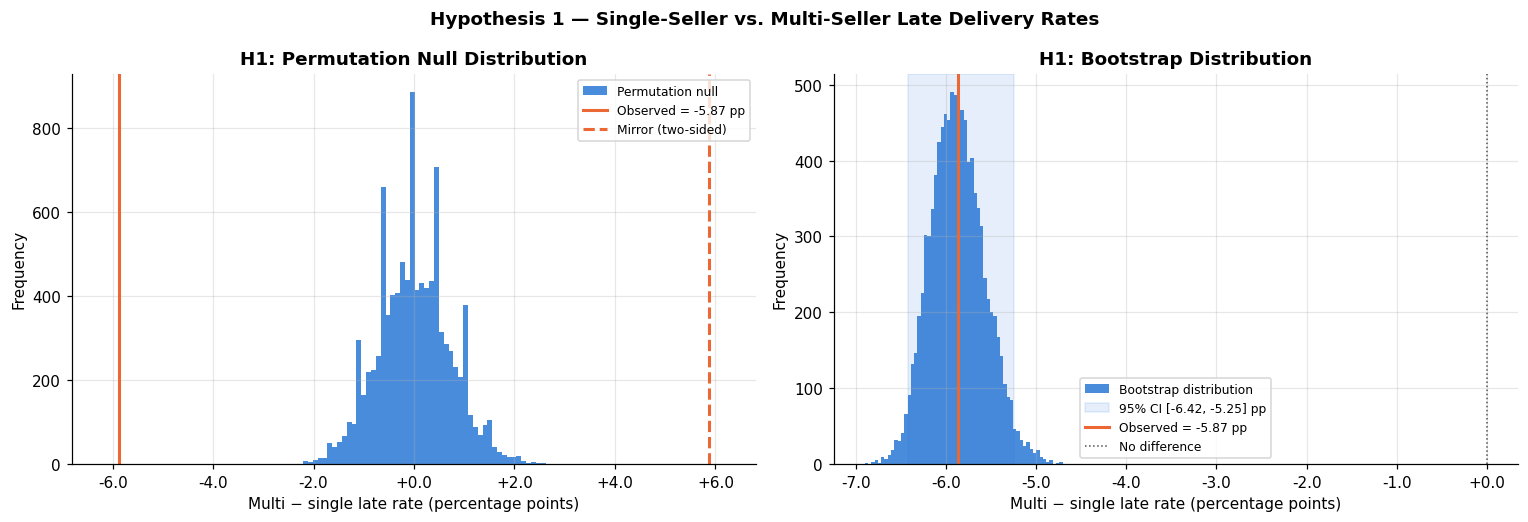

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
plot_null(axes[0], h1_null, h1_observed, 'H1: Permutation Null Distribution', 'Multi − single late rate')
plot_bootstrap(axes[1], h1_boot, h1_ci, h1_observed, 'H1: Bootstrap Distribution', 'Multi − single late rate')
fig.suptitle('Hypothesis 1 — Single-Seller vs. Multi-Seller Late Delivery Rates', fontweight='bold')
fig.tight_layout()
plt.show()

### 7. Conclusion for Hypothesis 1

- Multi-seller orders were late **1.05%** of the time (13 of 1,242 orders), compared with **6.92%** for single-seller orders, a difference of **−5.87 percentage points**.
- None of the 10,000 shuffled datasets produced a difference this extreme. The exact two-sided p-value is about **1.2 × 10⁻¹³**. The null distribution is close to symmetric, with 95% of its values between about −1.4 and +1.5 pp, so the small multi-seller group does not distort the test.
- The 95% bootstrap CI, **[−6.42, −5.25] pp**, excludes 0.

**Decision:** reject H₀. Single- and multi-seller orders have different late-delivery rates. The direction is the opposite of the intuition that more complex orders are riskier: multi-seller orders are late much **less** often.

**Limitation:** this is an association in observational data, not a causal effect. Multi-seller orders also differ in other ways (for example, more items and slightly longer promised windows), which Part 5 checks.

## Part 3: Hypothesis 2 — Shipping Costs

### 8. Observed late-delivery rates

An order is **high shipping cost** if its total freight is above the median (R$ 17.16). A median split creates two groups of nearly equal size. Group 1 = high freight, group 0 = low freight, so Δ > 0 means high-freight orders are late more often.

In [10]:
h2_summary = group_summary(y, high_freight, ('Low freight', 'High freight'))
display(h2_summary.round(4))

h2_observed = rate_difference(y, high_freight)
print(f'Observed difference (high - low): {h2_observed * 100:+.2f} percentage points')
print(f'Risk ratio (high / low): {y[high_freight].mean() / y[~high_freight].mean():.3f}')

,orders,late_orders,late_rate
group,,,
High freight,47488,3767,0.0793
Low freight,47616,2741,0.0576


Observed difference (high - low): +2.18 percentage points
Risk ratio (high / low): 1.378


### 9. Two-sided permutation test

Shuffle the high-freight labels 10,000 times.

In [11]:
h2_null = permutation_null(y, high_freight)
h2_p = two_sided_p(h2_null, h2_observed)
h2_exact_p = exact_permutation_p(y, high_freight)

print(f'Null distribution: mean = {h2_null.mean() * 100:+.3f} pp, sd = {h2_null.std() * 100:.3f} pp')
print(f'Null 2.5% / 97.5% quantiles: '
      f'{np.percentile(h2_null, 2.5) * 100:+.2f} / {np.percentile(h2_null, 97.5) * 100:+.2f} pp')
print(f'Observed difference: {h2_observed * 100:+.2f} pp')
print('Two-sided p-value (simulation):', format_p(h2_p))
print(f'Two-sided p-value (exact): {h2_exact_p:.2e}')

Null distribution: mean = -0.002 pp, sd = 0.163 pp
Null 2.5% / 97.5% quantiles: -0.32 / +0.32 pp
Observed difference: +2.18 pp
Two-sided p-value (simulation): < 1e-04 (0 of 10,000 permutations)
Two-sided p-value (exact): 2.14e-40


### 10. Bootstrap confidence interval

Resample orders with replacement within each freight group.

In [12]:
h2_boot = bootstrap_difference(y, high_freight)
h2_ci = percentile_ci(h2_boot)

print(f'95% bootstrap CI for the difference: '
      f'[{h2_ci[0] * 100:+.2f}, {h2_ci[1] * 100:+.2f}] percentage points')
print('CI excludes 0:', not (h2_ci[0] <= 0 <= h2_ci[1]))

95% bootstrap CI for the difference: [+1.86, +2.50] percentage points
CI excludes 0: True


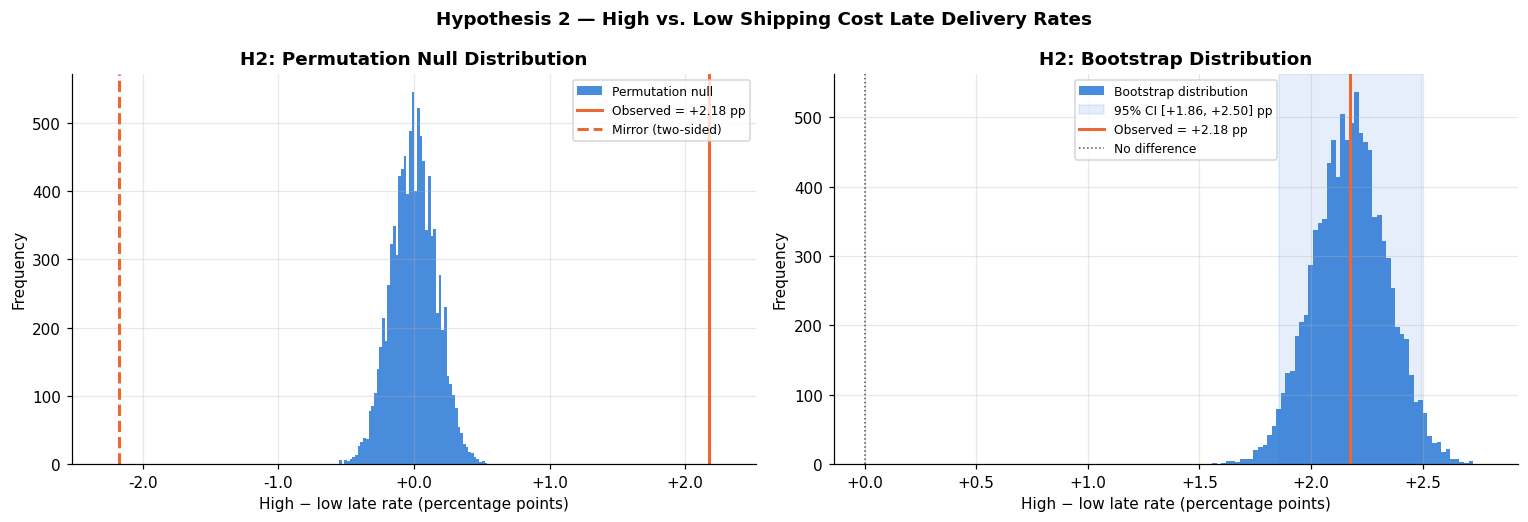

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
plot_null(axes[0], h2_null, h2_observed, 'H2: Permutation Null Distribution', 'High − low late rate')
plot_bootstrap(axes[1], h2_boot, h2_ci, h2_observed, 'H2: Bootstrap Distribution', 'High − low late rate')
fig.suptitle('Hypothesis 2 — High vs. Low Shipping Cost Late Delivery Rates', fontweight='bold')
fig.tight_layout()
plt.show()

### 11. Conclusion for Hypothesis 2

- Orders with above-median freight were late **7.93%** of the time, compared with **5.76%** for below-median orders, a difference of **+2.18 percentage points**.
- None of the 10,000 shuffled datasets produced a difference this extreme. The exact two-sided p-value is about **2.1 × 10⁻⁴⁰**.
- The 95% bootstrap CI, **[+1.86, +2.50] pp**, excludes 0.

**Decision:** reject H₀. High- and low-shipping-cost orders have different late-delivery rates: high-freight orders are late more often.

**Limitation:** this is an association, not a causal effect. The EDA showed that high-freight orders are concentrated in distant states with higher late rates, so geography may explain much of this difference. Part 5 checks this.

## Part 4: Results Summary

### 12. Primary test results

Collect the results of the two primary tests and apply the Holm correction.

In [14]:
def holm_adjust(p_values):
    """Holm step-down adjusted p-values (family-wise error rate control)."""
    p = np.asarray(p_values, float)
    adjusted = np.empty(len(p))
    running_max = 0.0
    for rank, idx in enumerate(np.argsort(p)):
        running_max = max(running_max, min(1.0, (len(p) - rank) * p[idx]))
        adjusted[idx] = running_max
    return adjusted


primary = pd.DataFrame({
    'difference_pp': [h1_observed * 100, h2_observed * 100],
    'ci_95_pp': [f'[{h1_ci[0] * 100:+.2f}, {h1_ci[1] * 100:+.2f}]',
                 f'[{h2_ci[0] * 100:+.2f}, {h2_ci[1] * 100:+.2f}]'],
    'p_simulation': [format_p(h1_p).split(' (')[0], format_p(h2_p).split(' (')[0]],
    'p_exact': [h1_exact_p, h2_exact_p],
}, index=['H1: multi − single seller', 'H2: high − low freight'])
primary['p_holm'] = holm_adjust(primary['p_exact'])
primary['reject_H0'] = primary['p_holm'] < ALPHA

display(primary.style.format({'difference_pp': '{:+.2f}', 'p_exact': '{:.2e}', 'p_holm': '{:.2e}'}))

,difference_pp,ci_95_pp,p_simulation,p_exact,p_holm,reject_H0
H1: multi − single seller,-5.87,"[-6.42, -5.25]",< 1e-04,1.20e-13,1.20e-13,True
H2: high − low freight,+2.18,"[+1.86, +2.50]",< 1e-04,2.14e-40,4.29e-40,True


Both null hypotheses are rejected after the Holm correction. The permutation tests and bootstrap CIs agree: in both cases the p-value is far below 0.05 and the 95% CI excludes 0.

## Part 5: Robustness Checks

The primary tests show that the groups differ, but not *why*. The EDA identified three variables that differ between the groups and also affect late risk: **purchase month**, **customer state**, and the **promised delivery window**. Here we check whether each result still holds when orders are compared within the same month, state, or promised-window range.

**Method.** For a set of strata (for example, each customer state), we compute the group difference *within* each stratum and combine them as a weighted average (Mantel–Haenszel weights $w_s = n_{1s} n_{0s} / n_s$). The stratified permutation test shuffles labels only within strata, and the CI comes from resampling within each stratum × group cell. We also fit a logistic regression with all control variables together.

These checks were chosen after the EDA, so they are reported as sensitivity analyses without multiple-testing correction.

In [15]:
def stratum_counts(y, group, strata):
    """Per-stratum group sizes and late counts."""
    table = pd.DataFrame({'y': y, 'g': group, 's': strata, 'y_g1': y * group})
    out = table.groupby('s').agg(n=('y', 'size'), late=('y', 'sum'),
                                 n1=('g', 'sum'), late1=('y_g1', 'sum'))
    out['n0'] = out['n'] - out['n1']
    out['late0'] = out['late'] - out['late1']
    return out


def adjusted_difference(late1, late0, n1, n0):
    """Mantel–Haenszel weighted within-stratum rate difference (vectorized over columns)."""
    n1 = np.asarray(n1, float).reshape(-1, 1)
    n0 = np.asarray(n0, float).reshape(-1, 1)
    late1 = np.asarray(late1, float).reshape(len(n1), -1)
    late0 = np.asarray(late0, float).reshape(len(n0), -1)
    valid = ((n1 > 0) & (n0 > 0)).ravel()
    n1, n0, late1, late0 = n1[valid], n0[valid], late1[valid], late0[valid]
    w = n1 * n0 / (n1 + n0)
    return (w * (late1 / n1 - late0 / n0)).sum(axis=0) / w.sum()


def stratified_permutation_p(y, group, strata, observed, n_iter=N_ITER, seed=SEED, batch=250):
    """Two-sided p-value when labels are shuffled only within strata."""
    rng = np.random.default_rng(seed)
    codes, uniques = pd.factorize(strata)
    n1_s, n0_s, late_s = [], [], []
    late1_null = np.empty((len(uniques), n_iter))
    for s in range(len(uniques)):
        idx = codes == s
        y_s, g_s = y[idx].astype(np.float32), group[idx]
        n1_s.append(g_s.sum()); n0_s.append((~g_s).sum()); late_s.append(y_s.sum())
        for start in range(0, n_iter, batch):
            b = min(batch, n_iter - start)
            perm = rng.permuted(np.tile(g_s, (b, 1)), axis=1).astype(np.float32)
            late1_null[s, start:start + b] = perm @ y_s
    null = adjusted_difference(late1_null, np.array(late_s)[:, None] - late1_null, n1_s, n0_s)
    return two_sided_p(null, observed)


def stratified_ci(counts, n_boot=N_ITER, seed=SEED):
    """95% CI for the adjusted difference, resampling within each stratum x group cell.

    Resampling n binary outcomes with replacement gives a late count that follows
    Binomial(n, p_hat) exactly, so each cell is drawn directly from that distribution.
    """
    rng = np.random.default_rng(seed)
    n1, n0 = counts['n1'].to_numpy(int), counts['n0'].to_numpy(int)
    p1 = np.divide(counts['late1'].to_numpy(float), n1, out=np.zeros(len(n1)), where=n1 > 0)
    p0 = np.divide(counts['late0'].to_numpy(float), n0, out=np.zeros(len(n0)), where=n0 > 0)
    late1 = rng.binomial(n1[:, None], p1[:, None], (len(n1), n_boot))
    late0 = rng.binomial(n0[:, None], p0[:, None], (len(n0), n_boot))
    return percentile_ci(adjusted_difference(late1, late0, n1, n0))


def robustness_table(y, group, strata_options, permutation_test_for=()):
    """Adjusted difference, 95% CI, and (optionally) stratified permutation p-value."""
    rows = []
    for name, strata in strata_options.items():
        counts = stratum_counts(y, group, strata)
        est = adjusted_difference(counts['late1'], counts['late0'], counts['n1'], counts['n0'])[0]
        ci = stratified_ci(counts)
        p = (format_p(stratified_permutation_p(y, group, strata, est)).split(' (')[0]
             if name in permutation_test_for else '—')
        rows.append({'compared_within': name, 'difference_pp': est * 100,
                     'ci_low_pp': ci[0] * 100, 'ci_high_pp': ci[1] * 100,
                     'stratified_permutation_p': p})
    return pd.DataFrame(rows).set_index('compared_within').round(2)


def logit_odds_ratio(formula, term, data):
    """Odds ratio, 95% CI, and p-value for one term of a logistic regression."""
    model = smf.logit(formula, data=data).fit(disp=0, method='bfgs', maxiter=5000)
    if not model.mle_retvals['converged']:
        raise RuntimeError(f'Logistic regression did not converge: {formula}')
    ci = np.exp(model.conf_int().loc[term])
    return {'odds_ratio': np.exp(model.params[term]), 'or_ci_low': ci[0],
            'or_ci_high': ci[1], 'p_value': model.pvalues[term]}

In [16]:
# Stratification variables
month = df['order_purchase_timestamp'].dt.to_period('M').astype(str)
state = df['customer_state']
promise_q = pd.qcut(df['promised_delivery_days'], 5, labels=False).astype(str)
freight_q = pd.qcut(df['total_freight'], 5, labels=False).astype(str)

# Regression controls (months with fewer than 100 orders are pooled)
df['month_group'] = np.where(month.map(month.value_counts()) >= 100, month, 'sparse')
df['multi_seller'] = multi_seller.astype(int)
df['high_freight'] = high_freight.astype(int)
CONTROLS = ('C(customer_state) + C(month_group) + np.log1p(total_price) '
            '+ item_count + approval_duration_hours')

### 13. Robustness of Hypothesis 1

Compare single- and multi-seller orders within the same month, state, promised-window quintile, and freight quintile, and within combinations of these.

In [17]:
h1_robust = robustness_table(y, multi_seller, {
    'All orders (primary test)': np.zeros(len(df), dtype=int),
    'Purchase month': month.to_numpy(),
    'Customer state': state.to_numpy(),
    'Promised window (quintile)': promise_q.to_numpy(),
    'Freight (quintile)': freight_q.to_numpy(),
    'State x promised window': (state + '|' + promise_q).to_numpy(),
}, permutation_test_for={'Purchase month'})
display(h1_robust)

h1_logit = logit_odds_ratio(
    f'late_delivery ~ multi_seller + {CONTROLS} + promised_delivery_days + np.log1p(total_freight)',
    'multi_seller', df)
print('Logistic regression with all controls '
      '(state, month, promised window, freight, price, item count, approval time):')
print(f"  Odds ratio for multi-seller: {h1_logit['odds_ratio']:.3f} "
      f"(95% CI [{h1_logit['or_ci_low']:.3f}, {h1_logit['or_ci_high']:.3f}]), "
      f"p = {h1_logit['p_value']:.2e}")

,difference_pp,ci_low_pp,ci_high_pp,stratified_permutation_p
compared_within,,,,
All orders (primary test),-5.87,-6.42,-5.26,—
Purchase month,-5.55,-6.10,-4.96,< 1e-04
Customer state,-5.63,-6.17,-5.01,—
Promised window (quintile),-5.86,-6.41,-5.24,—
Freight (quintile),-7.34,-7.95,-6.67,—
State x promised window,-5.18,-5.69,-4.61,—


Logistic regression with all controls (state, month, promised window, freight, price, item count, approval time):
  Odds ratio for multi-seller: 0.174 (95% CI [0.100, 0.301]), p = 4.83e-10


**H1 is robust.** The difference stays between about −5 and −7 percentage points under every comparison, and the logistic regression gives an odds ratio of about 0.17 (95% CI about 0.10–0.30). In particular, comparing orders with the same promised window leaves the gap almost unchanged, so the lower late rate of multi-seller orders is **not** explained by longer delivery promises. Its cause remains unknown with the current data.

### 14. Robustness of Hypothesis 2

Compare high- and low-freight orders within the same state, and within the same state *and* promised-window quintile. High-freight orders tend to receive longer promised windows, and the EDA (Section 10.1) showed that within a state, a longer window strongly lowers late risk. Controlling for state alone could therefore hide part of the freight effect.

In [18]:
print('Median promised delivery days — high freight:',
      df.loc[high_freight, 'promised_delivery_days'].median(),
      '| low freight:', df.loc[~high_freight, 'promised_delivery_days'].median())

h2_robust = robustness_table(y, high_freight, {
    'All orders (primary test)': np.zeros(len(df), dtype=int),
    'Purchase month': month.to_numpy(),
    'Customer state': state.to_numpy(),
    'State x promised window': (state + '|' + promise_q).to_numpy(),
}, permutation_test_for={'Customer state', 'State x promised window'})
display(h2_robust)

h2_logit = pd.DataFrame([
    logit_odds_ratio(f'late_delivery ~ high_freight + {CONTROLS}', 'high_freight', df),
    logit_odds_ratio(f'late_delivery ~ high_freight + {CONTROLS} + promised_delivery_days',
                     'high_freight', df),
], index=['Controls without promised window', 'Controls + promised window'])
print('Logistic regression: odds ratio for high freight')
print('(controls: state, month, price, item count, approval time)')
display(h2_logit.style.format({'odds_ratio': '{:.3f}', 'or_ci_low': '{:.3f}',
                               'or_ci_high': '{:.3f}', 'p_value': '{:.2e}'}))

Median promised delivery days — high freight: 26.0 | low freight: 21.0


,difference_pp,ci_low_pp,ci_high_pp,stratified_permutation_p
compared_within,,,,
All orders (primary test),2.18,1.86,2.50,—
Purchase month,2.31,1.99,2.63,—
Customer state,0.26,-0.09,0.61,0.1508
State x promised window,0.98,0.63,1.34,< 1e-04


Logistic regression: odds ratio for high freight
(controls: state, month, price, item count, approval time)


,odds_ratio,or_ci_low,or_ci_high,p_value
Controls without promised window,1.031,0.966,1.101,3.57e-01
Controls + promised window,1.296,1.210,1.387,1.05e-13


**H2 is mostly, but not entirely, explained by geography.**

- **Within the same state**, the difference drops from +2.18 to about **+0.26 pp** and is no longer significant (p ≈ 0.15). About 88% of the raw gap therefore reflects *where* high-freight orders are shipped.
- **Within the same state and promised-window quintile**, the difference rises again to about **+1 pp** and is significant (p < 0.0001). High-freight orders receive longer promised windows (median 26 vs. 21 days), which protect against delay and hide part of the freight effect when only state is controlled.
- The logistic regression shows the same pattern: the odds ratio for high freight is about 1.03 (not significant) without the promised window, and about **1.30** (95% CI about 1.21–1.39) with it.

So the state-only result should not be read as "freight has no effect." Among orders with the same destination state and the same promised window, high-freight orders are still somewhat more likely to be late. This residual effect may reflect factors not in our data, such as distance within a state or package size.

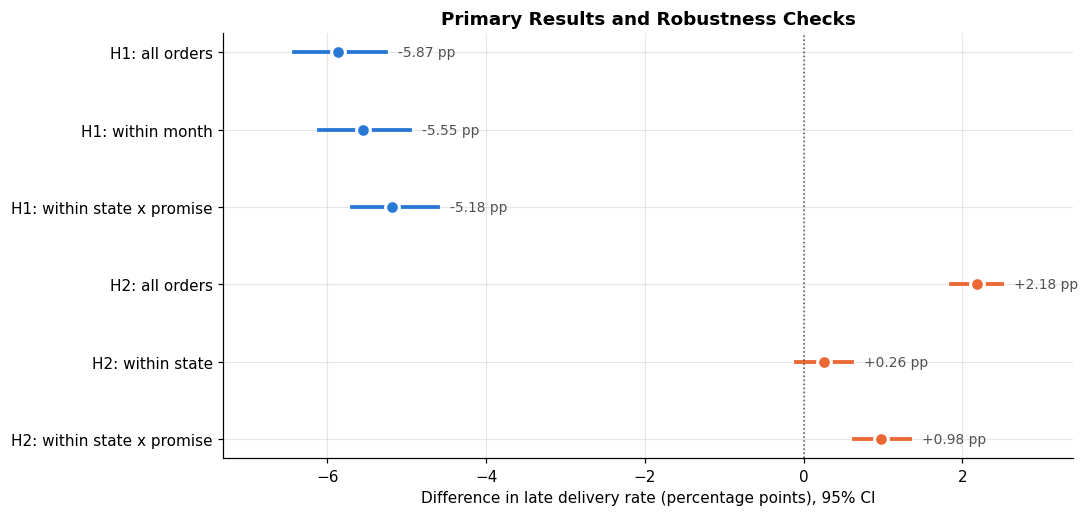

In [19]:
fig, ax = plt.subplots(figsize=(10, 4.8))
rows = [
    ('H1: all orders', h1_robust.loc['All orders (primary test)'], BLUE),
    ('H1: within month', h1_robust.loc['Purchase month'], BLUE),
    ('H1: within state x promise', h1_robust.loc['State x promised window'], BLUE),
    ('H2: all orders', h2_robust.loc['All orders (primary test)'], ORANGE),
    ('H2: within state', h2_robust.loc['Customer state'], ORANGE),
    ('H2: within state x promise', h2_robust.loc['State x promised window'], ORANGE),
]
for i, (label, row, color) in enumerate(rows):
    ax.plot([row['ci_low_pp'], row['ci_high_pp']], [i, i], color=color, linewidth=2.5)
    ax.plot(row['difference_pp'], i, 'o', color=color, markersize=9,
            markeredgecolor='white', markeredgewidth=2)
    ax.annotate(f"{row['difference_pp']:+.2f} pp", (row['ci_high_pp'], i), xytext=(8, 0),
                textcoords='offset points', va='center', fontsize=9, color=INK)
ax.axvline(0, color=INK, linewidth=1, linestyle=':')
ax.margins(x=0.1)
ax.set_yticks(range(len(rows)))
ax.set_yticklabels([r[0] for r in rows])
ax.invert_yaxis()
ax.set_xlabel('Difference in late delivery rate (percentage points), 95% CI')
ax.set_title('Primary Results and Robustness Checks')
fig.tight_layout()
plt.show()

## Part 6: Final Conclusions

### 1. Summary of Findings

| Hypothesis | Primary test | Robustness checks | Conclusion |
|---|---|---|---|
| **H1: Order complexity** | −5.87 pp, 95% CI [−6.42, −5.25], exact p ≈ 1.2 × 10⁻¹³ | Holds within month, state, and promised window (about −5 to −7 pp) | Reject H₀. Multi-seller orders are late **less** often. |
| **H2: Shipping costs** | +2.18 pp, 95% CI [+1.86, +2.50], exact p ≈ 2.1 × 10⁻⁴⁰ | About +0.3 pp within state (n.s.); about +1 pp within state × promised window | Reject H₀. Mostly explained by geography, with a smaller remaining effect. |

Both primary decisions hold after the Holm correction.

### 2. Notes on Interpretation

- The robustness checks show that the H1 result is stable, while the raw H2 result mixes a geographic effect with a smaller freight effect. Seller location, exact distance, and product size are not in the current data, so some confounding may remain.

### 3. Implications for Modeling

1. **Seller count** is a useful feature: multi-seller orders carry clearly lower delay risk, though the group is small.
2. **Freight, customer state, and promised window** should be modeled together. Freight is mostly a geography signal but adds some information once state and promised window are known. Tree-based models can capture these interactions.
3. Adding **seller location, distance, and product dimensions** (from other Olist tables) could explain the residual freight effect.
4. Because late rates vary strongly by month, a **time-based** train/test split is recommended.